## Import Libraries

In [2]:
import warnings
import numpy as np
import pandas as pd
import joblib
from pathlib import Path

import mlflow
import mlflow.sklearn
import mlflow.lightgbm

import optuna
import lightgbm as lgb
import shap

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_PATH = "processed_data/forecast_24h.parquet"
MLFLOW_DB = "sqlite:///mlflow.db"
EXPERIMENT_NAME = "solarvision_forecast_24h"

df = pd.read_parquet(DATA_PATH)
print("Dataset:", df.shape)

c:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset: (4272, 42)


## Modeling

In [3]:
# features 
features = [
    "hour", "dayofweek", "month", "dayofyear",
    "hour_sin", "hour_cos", "doy_sin", "doy_cos",
    "is_daytime",

    "P_dusty_lag_1h", "P_dusty_lag_3h", "P_dusty_lag_6h",
    "P_dusty_lag_12h", "P_dusty_lag_24h", "P_dusty_lag_48h",
    "P_dusty_lag_72h",

    "P_dusty_roll_mean_3h", "P_dusty_roll_mean_6h",
    "P_dusty_roll_mean_12h", "P_dusty_roll_mean_24h",
    "P_dusty_roll_max_24h",

    "dust_density_reconstructed_PCHIP_gm2",
    "dust_lag_24h",
    "dust_roll_mean_24h",
    "dust_roll_max_24h",

    "temp_amb_C", "T_cell_C", "RH_pct",
    "wind_speed_ms", "cloud_cover_pct", "precipitation_mm"
]


In [4]:
# splitting the dataset into train, validation, and test sets
target = "target_P_dusty_24h"

n = len(df)

train_df = df.iloc[:int(n * 0.70)]
val_df = df.iloc[int(n * 0.70):int(n * 0.85)]
test_df = df.iloc[int(n * 0.85):]

X_train, y_train = train_df[features], train_df[target]
X_val, y_val = val_df[features], val_df[target]
X_test, y_test = test_df[features], test_df[target]

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (2990, 31)
Validation: (641, 31)
Test: (641, 31)


In [5]:
# defining a function to calculate regression metrics
def regression_metrics(y_true, y_pred, model_name):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    mae = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    r2 = r2_score(y_true, y_pred)

    daytime = y_true > 0.1
    mape = np.mean(
        np.abs((y_true[daytime] - y_pred[daytime]) / y_true[daytime])
    ) * 100

    return {
        "model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape,
        "R2": r2
    }
# Production at night is usually zero, so we calculate MAPE only for daytime values. 

In [ ]:
# MLflow setup
mlflow.set_tracking_uri(MLFLOW_DB)
mlflow.set_experiment(EXPERIMENT_NAME)

print("MLflow tracking URI:", mlflow.get_tracking_uri())

2026/10/24 18:25:23 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/24 18:25:23 INFO mlflow.store.db.utils: Updating database tables
2026/10/24 18:25:25 INFO mlflow.tracking.fluent: Experiment with name 'solarvision_forecast_24h' does not exist. Creating a new experiment.


MLflow tracking URI: sqlite:///mlflow.db


In [7]:
# Ridge Regression
ridge = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0, random_state=RANDOM_STATE)
)

with mlflow.start_run(run_name="ridge_baseline"):
    ridge.fit(X_train, y_train)
    ridge_val_pred = ridge.predict(X_val)

    ridge_metrics = regression_metrics(
        y_val, ridge_val_pred, "Ridge Regression"
    )

    mlflow.log_params({
        "model_family": "linear",
        "alpha": 1.0,
        "features": len(features)
    })

    mlflow.log_metrics({
        "MAE": ridge_metrics["MAE"],
        "RMSE": ridge_metrics["RMSE"],
        "MAPE": ridge_metrics["MAPE"],
        "R2": ridge_metrics["R2"]
    })

    mlflow.sklearn.log_model(ridge, "model")

ridge_metrics

2026/10/24 18:25:49 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


{'model': 'Ridge Regression',
 'MAE': 2.184639760245851,
 'RMSE': 3.4134031721599154,
 'MAPE': np.float64(43.72688995206943),
 'R2': 0.9692675512913823}

In [10]:
# Random Forest
rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=RANDOM_STATE
)

with mlflow.start_run(run_name="random_forest_default"):
    rf.fit(X_train, y_train)
    rf_val_pred = rf.predict(X_val)

    rf_metrics = regression_metrics(
        y_val, rf_val_pred, "Random Forest"
    )

    mlflow.log_params({
        "model_family": "tree_ensemble",
        "n_estimators": 300,
        "max_depth": 15,
        "min_samples_leaf": 2
    })

    mlflow.log_metrics({
        "MAE": rf_metrics["MAE"],
        "RMSE": rf_metrics["RMSE"],
        "MAPE": rf_metrics["MAPE"],
        "R2": rf_metrics["R2"]
    })

    mlflow.sklearn.log_model(
    rf,
    "model",
    skops_trusted_types=["sklearn.tree._tree.Tree"]
    )

rf_metrics

2026/10/24 18:29:01 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


{'model': 'Random Forest',
 'MAE': 1.34240835958523,
 'RMSE': 3.562513755985609,
 'MAPE': np.float64(16.87339000117803),
 'R2': 0.9665238820101827}

In [9]:
# LightGBM
lgbm = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1
)

with mlflow.start_run(run_name="lightgbm_default"):
    lgbm.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        eval_metric="l1"
    )

    lgb_val_pred = lgbm.predict(X_val)

    lgb_metrics = regression_metrics(
        y_val, lgb_val_pred, "LightGBM"
    )

    mlflow.log_params({
        "model_family": "boosting",
        "n_estimators": 500,
        "learning_rate": 0.05,
        "num_leaves": 31
    })

    mlflow.log_metrics({
        "MAE": lgb_metrics["MAE"],
        "RMSE": lgb_metrics["RMSE"],
        "MAPE": lgb_metrics["MAPE"],
        "R2": lgb_metrics["R2"]
    })

    mlflow.lightgbm.log_model(lgbm, "model")

lgb_metrics

2026/10/24 18:27:37 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


{'model': 'LightGBM',
 'MAE': 1.4251768808639218,
 'RMSE': 3.5241561924126303,
 'MAPE': np.float64(17.38286364446722),
 'R2': 0.9672408754961871}

### Model Comparison — 24-Hour PV Power Forecast

Three model families were trained and evaluated on a chronologically split validation set:

- **Ridge Regression (Linear model):** achieved the highest \(R^2\) (0.969) and a competitive RMSE, but produced the highest MAPE (43.73%), indicating weaker performance during low-power periods.
- **Random Forest (Tree ensemble):** achieved the best MAE (1.342 W) and the best MAPE (16.87%), making it the strongest model for typical hourly power prediction.
- **LightGBM (Gradient boosting):** achieved the best RMSE (3.524 W) and a strong \(R^2\) (0.967), with performance very close to Random Forest.

All models explain more than 96% of the variance in the validation data.  
Random Forest is currently the best choice by MAE and MAPE, while LightGBM is the best balanced candidate for further tuning with Optuna.

In [13]:
comparison_results = pd.DataFrame([
    ridge_metrics,
    rf_metrics,
    lgb_metrics
])

comparison_results = comparison_results.sort_values(
    by="MAE",
    ascending=True
).reset_index(drop=True)

comparison_results["MAE"] = comparison_results["MAE"].round(3)
comparison_results["RMSE"] = comparison_results["RMSE"].round(3)
comparison_results["MAPE"] = comparison_results["MAPE"].round(2)
comparison_results["R2"] = comparison_results["R2"].round(4)

comparison_results

,model,MAE,RMSE,MAPE,R2
0,Random Forest,1.342,3.563,16.87,0.9665
1,LightGBM,1.425,3.524,17.38,0.9672
2,Ridge Regression,2.185,3.413,43.73,0.9693


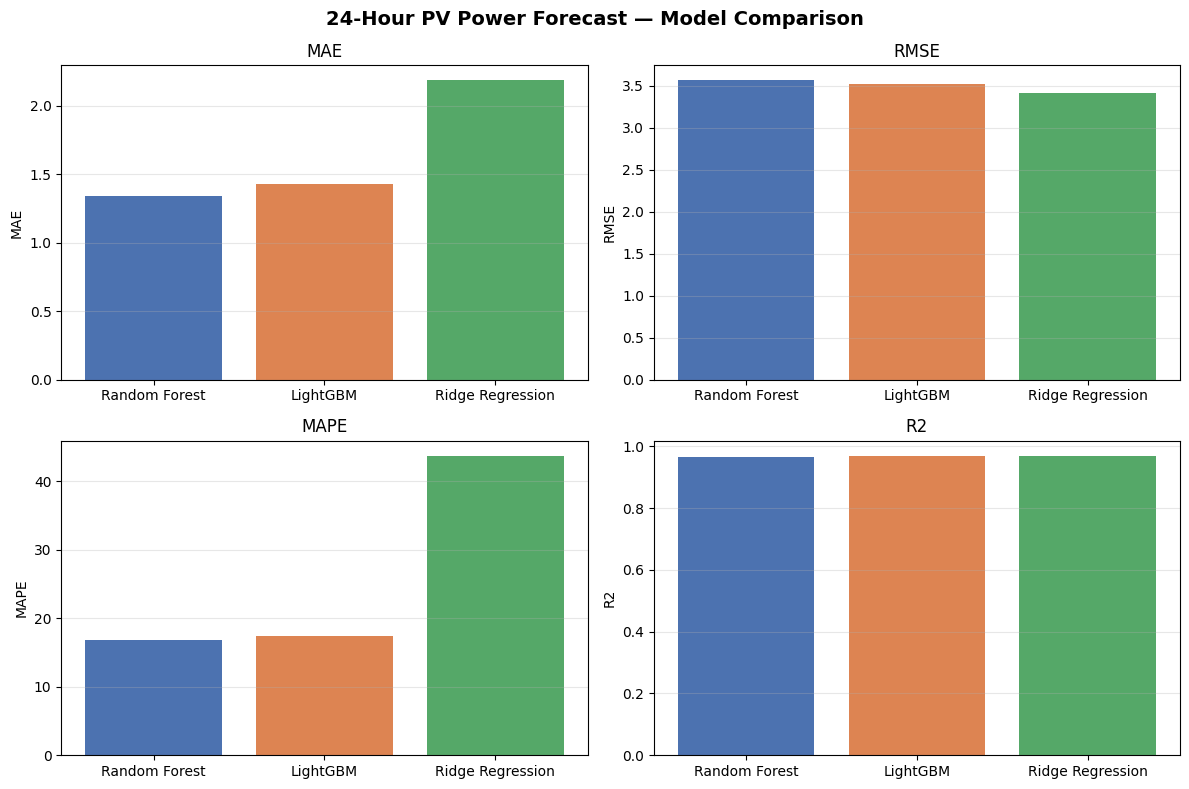

In [14]:
import matplotlib.pyplot as plt

metrics_to_plot = ["MAE", "RMSE", "MAPE", "R2"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, metric in enumerate(metrics_to_plot):
    axes[i].bar(
        comparison_results["model"],
        comparison_results[metric],
        color=["#4C72B0", "#DD8452", "#55A868"]
    )
    axes[i].set_title(metric)
    axes[i].set_ylabel(metric)
    axes[i].grid(axis="y", alpha=0.3)

plt.suptitle(
    "24-Hour PV Power Forecast — Model Comparison",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig("model_comparison_24h.png", dpi=150, bbox_inches="tight")
plt.show()

## Optuna + TimeSeriesSplit

#### Hyperparameter Tuning — LightGBM with Optuna
- We tune LightGBM using Optuna and time-series cross-validation.  
The search is performed only on the training set to avoid data leakage.

In [15]:
tscv = TimeSeriesSplit(n_splits=3)

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 200, 700),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 63),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 60),
        "subsample": trial.suggest_float("subsample", 0.7, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.7, 1.0),
        "random_state": RANDOM_STATE,
        "n_jobs": -1,
        "verbose": -1
    }

    maes = []

    for train_idx, valid_idx in tscv.split(X_train):
        X_tr, y_tr = X_train.iloc[train_idx], y_train.iloc[train_idx]
        X_cv, y_cv = X_train.iloc[valid_idx], y_train.iloc[valid_idx]

        model = lgb.LGBMRegressor(**params)
        model.fit(X_tr, y_tr)

        pred = model.predict(X_cv)
        maes.append(mean_absolute_error(y_cv, pred))

    return np.mean(maes)

study = optuna.create_study(
    direction="minimize",
    study_name="lightgbm_tuning",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE)
)

study.optimize(objective, n_trials=20, show_progress_bar=True)

print("Best MAE:", study.best_value)
print("Best params:", study.best_params)

[I 2026-10-24 18:35:30,759] A new study created in memory with name: lightgbm_tuning
Best trial: 0. Best value: 6.2441:   5%|▌         | 1/20 [00:00<00:16,  1.13it/s]

[I 2026-10-24 18:35:31,646] Trial 0 finished with value: 6.244099550569454 and parameters: {'n_estimators': 387, 'learning_rate': 0.13125830316209655, 'num_leaves': 50, 'min_child_samples': 40, 'subsample': 0.7468055921327309, 'colsample_bytree': 0.7467983561008608}. Best is trial 0 with value: 6.244099550569454.


Best trial: 1. Best value: 6.21901:  10%|█         | 2/20 [00:01<00:11,  1.51it/s]

[I 2026-10-24 18:35:32,150] Trial 1 finished with value: 6.219012441461562 and parameters: {'n_estimators': 229, 'learning_rate': 0.10440040750544663, 'num_leaves': 44, 'min_child_samples': 46, 'subsample': 0.7061753482887407, 'colsample_bytree': 0.9909729556485982}. Best is trial 1 with value: 6.219012441461562.


Best trial: 2. Best value: 6.03955:  15%|█▌        | 3/20 [00:02<00:14,  1.18it/s]

...

[I 2026-10-24 18:35:51,890] Trial 17 finished with value: 5.387924673313016 and parameters: {'n_estimators': 220, 'learning_rate': 0.02121078018395853, 'num_leaves': 32, 'min_child_samples': 36, 'subsample': 0.7219175881510601, 'colsample_bytree': 0.723166071831974}. Best is trial 17 with value: 5.387924673313016.


Best trial: 17. Best value: 5.38792:  95%|█████████▌| 19/20 [00:21<00:01,  1.07s/it]

[I 2026-10-24 18:35:52,558] Trial 18 finished with value: 5.839225958631784 and parameters: {'n_estimators': 217, 'learning_rate': 0.024436309454221206, 'num_leaves': 17, 'min_child_samples': 22, 'subsample': 0.7530426301293008, 'colsample_bytree': 0.7419856618358636}. Best is trial 17 with value: 5.387924673313016.


Best trial: 17. Best value: 5.38792: 100%|██████████| 20/20 [00:22<00:00,  1.14s/it]

[I 2026-10-24 18:35:53,473] Trial 19 finished with value: 5.65332332469226 and parameters: {'n_estimators': 305, 'learning_rate': 0.025450363671536684, 'num_leaves': 28, 'min_child_samples': 31, 'subsample': 0.7356009416551045, 'colsample_bytree': 0.7374609356357205}. Best is trial 17 with value: 5.387924673313016.
Best MAE: 5.387924673313016
Best params: {'n_estimators': 220, 'learning_rate': 0.02121078018395853, 'num_leaves': 32, 'min_child_samples': 36, 'subsample': 0.7219175881510601, 'colsample_bytree': 0.723166071831974}


#### Train Final LightGBM Model
- The best hyperparameters found by Optuna are used to train the final LightGBM model.  
- Validation data is used only for early evaluation, while the test set remains untouched.

In [16]:
# Train the best LightGBM model with the optimal hyperparameters and log it to MLflow
best_params = study.best_params.copy()
best_params.update({
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
    "verbose": -1
})

best_lgbm = lgb.LGBMRegressor(**best_params)

with mlflow.start_run(run_name="lightgbm_optuna_best"):
    best_lgbm.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        eval_metric="l1"
    )

    best_val_pred = best_lgbm.predict(X_val)

    best_metrics = regression_metrics(
        y_val, best_val_pred, "LightGBM Optuna"
    )

    mlflow.log_params({
        "model_family": "boosting",
        "tuning": "optuna",
        "cv": "TimeSeriesSplit_3",
        **best_params
    })

    mlflow.log_metrics({
        "MAE": best_metrics["MAE"],
        "RMSE": best_metrics["RMSE"],
        "MAPE": best_metrics["MAPE"],
        "R2": best_metrics["R2"]
    })

    mlflow.lightgbm.log_model(best_lgbm, "model")

best_metrics

2026/10/24 18:36:22 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


{'model': 'LightGBM Optuna',
 'MAE': 1.2459928857430562,
 'RMSE': 3.261378962013466,
 'MAPE': np.float64(15.368716285963298),
 'R2': 0.9719440795961289}

#### Final Model Comparison
- The tuned LightGBM model is compared with Ridge Regression, Random Forest, and the default LightGBM model.

In [18]:
comparison_results = pd.DataFrame([
    ridge_metrics,
    rf_metrics,
    lgb_metrics,
    best_metrics
])

comparison_results = comparison_results.sort_values(
    by="MAE",
    ascending=True
).reset_index(drop=True)

comparison_results[["MAE", "RMSE", "MAPE", "R2"]] = comparison_results[
    ["MAE", "RMSE", "MAPE", "R2"]
].round(3)

comparison_results

,model,MAE,RMSE,MAPE,R2
0,LightGBM Optuna,1.246,3.261,15.369,0.972
1,Random Forest,1.342,3.563,16.873,0.967
2,LightGBM,1.425,3.524,17.383,0.967
3,Ridge Regression,2.185,3.413,43.727,0.969


####  Model Comparison Plot

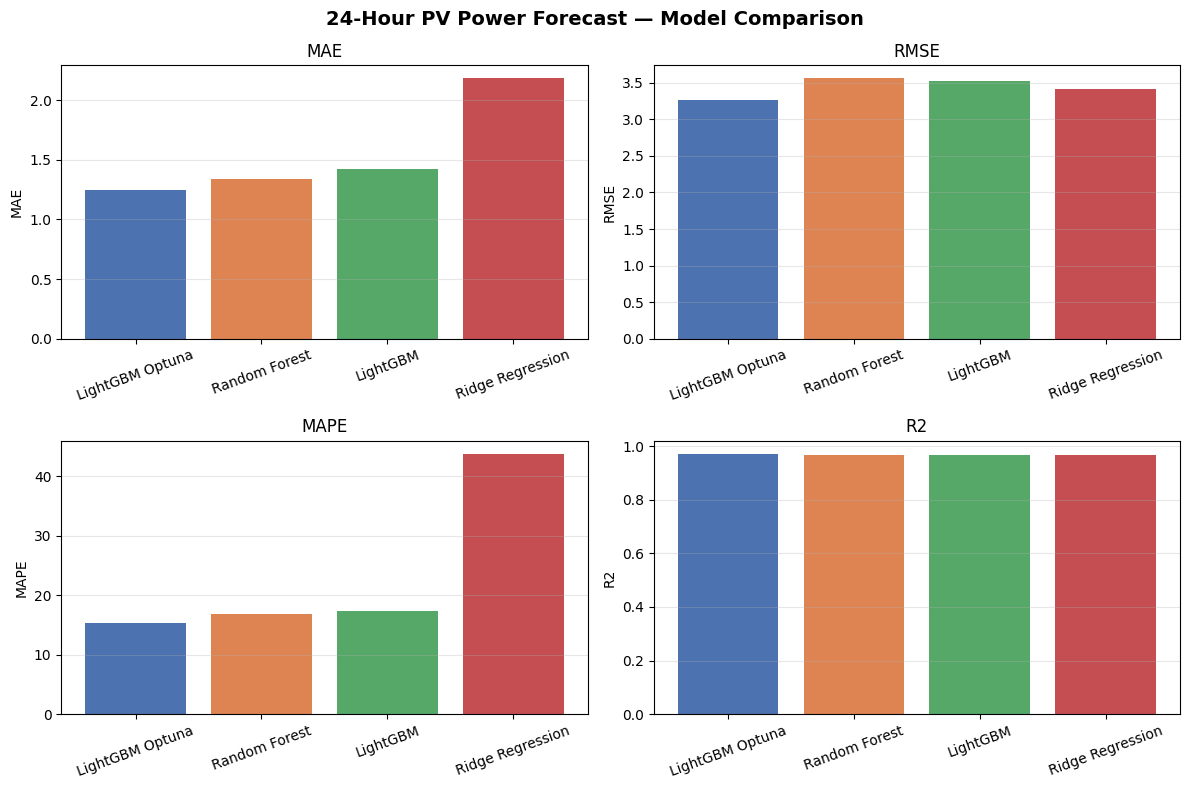

In [24]:
import matplotlib.pyplot as plt

metrics_to_plot = ["MAE", "RMSE", "MAPE", "R2"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

colors = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]

for i, metric in enumerate(metrics_to_plot):
    axes[i].bar(
        all_results["model"],
        all_results[metric],
        color=colors[:len(all_results)]
    )

    axes[i].set_title(metric)
    axes[i].set_ylabel(metric)
    axes[i].grid(axis="y", alpha=0.3)
    axes[i].tick_params(axis="x", rotation=20)

plt.suptitle(
    "24-Hour PV Power Forecast — Model Comparison",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig("model_comparison_24h.png", dpi=150, bbox_inches="tight")
plt.show()

## SHAP

#### Model Explainability with SHAP
- SHAP values explain how each feature contributed to individual predictions of the tuned LightGBM model.

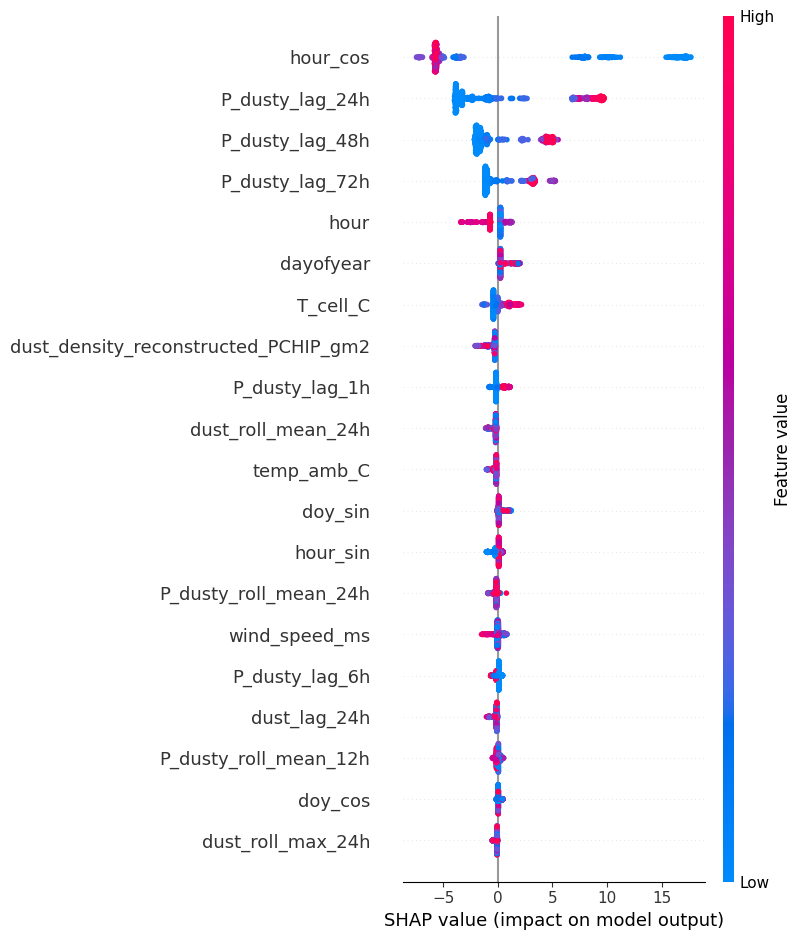

In [19]:
explainer = shap.TreeExplainer(best_lgbm)
shap_values = explainer.shap_values(X_val)

shap.summary_plot(
    shap_values,
    X_val,
    feature_names=features,
    show=True
)

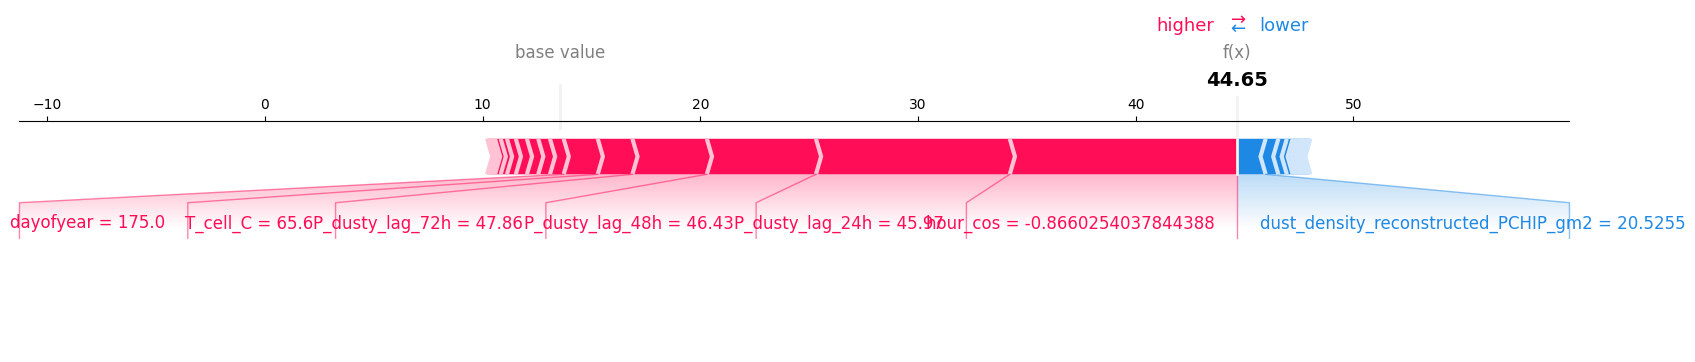

In [20]:
sample_idx = 0

shap.force_plot(
    explainer.expected_value,
    shap_values[sample_idx, :],
    X_val.iloc[sample_idx, :],
    matplotlib=True,
    show=True
)

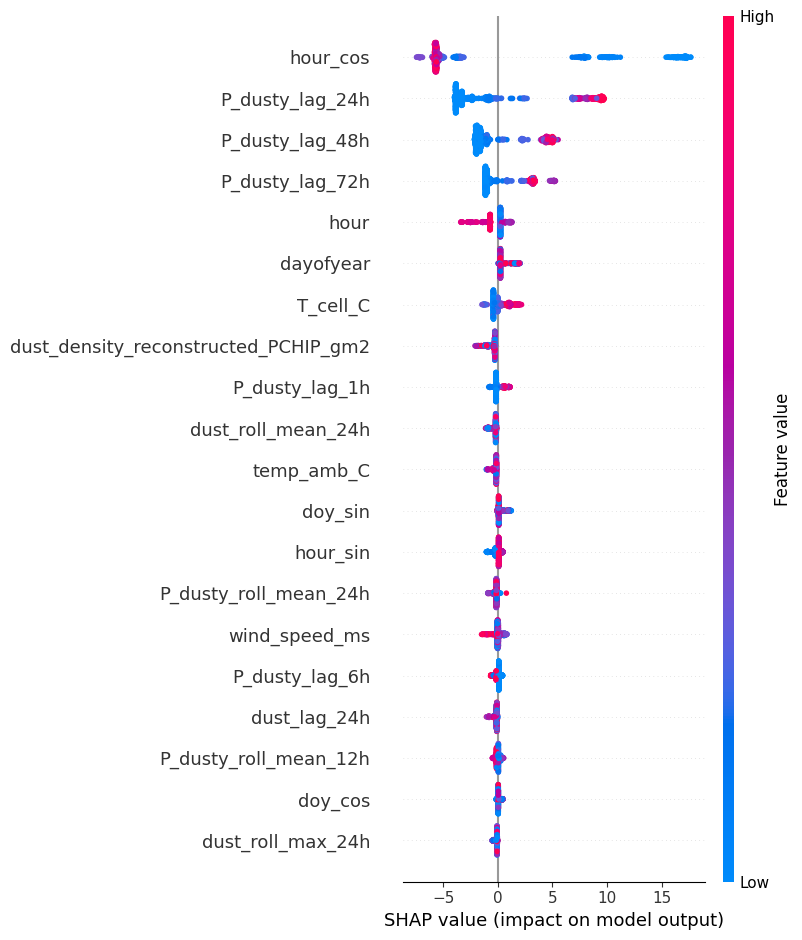

In [21]:
plt = shap.summary_plot(
    shap_values,
    X_val,
    feature_names=features,
    show=False
)

import matplotlib.pyplot as plt
plt.savefig("shap_summary_24h.png", bbox_inches="tight", dpi=150)

## Select Final Model

The final model is selected based on validation MAE.  
If the tuned LightGBM model has the lowest MAE, it is selected; otherwise, Random Forest is selected.

In [25]:
models_to_compare = {
    "Ridge Regression": {
        "model": ridge,
        "metrics": ridge_metrics,
        "predictions": ridge_val_pred
    },
    "Random Forest": {
        "model": rf,
        "metrics": rf_metrics,
        "predictions": rf_val_pred
    },
    "LightGBM Optuna": {
        "model": best_lgbm,
        "metrics": best_metrics,
        "predictions": best_val_pred
    }
}

best_model_name = min(
    models_to_compare,
    key=lambda name: models_to_compare[name]["metrics"]["MAE"]
)

final_model = models_to_compare[best_model_name]["model"]
final_val_pred = models_to_compare[best_model_name]["predictions"]

print("Selected final model:", best_model_name)
print(models_to_compare[best_model_name]["metrics"])

Selected final model: LightGBM Optuna
{'model': 'LightGBM Optuna', 'MAE': 1.2459928857430562, 'RMSE': 3.261378962013466, 'MAPE': np.float64(15.368716285963298), 'R2': 0.9719440795961289}


## Testing

The test set is evaluated only once, after model selection and tuning are complete.

In [27]:
final_test_pred = final_model.predict(X_test)

final_test_metrics = regression_metrics(
    y_test,
    final_test_pred,
    f"{best_model_name} - Test"
)

baseline_test_pred = X_test["P_dusty_lag_24h"]

baseline_test_metrics = regression_metrics(
    y_test,
    baseline_test_pred,
    "Baseline Persistence - Test"
)

test_comparison = pd.DataFrame([
    baseline_test_metrics,
    final_test_metrics
])

test_comparison[["MAE", "RMSE", "MAPE", "R2"]] = test_comparison[
    ["MAE", "RMSE", "MAPE", "R2"]
].round(3)

test_comparison

,model,MAE,RMSE,MAPE,R2
0,Baseline Persistence - Test,1.039,3.271,12.029,0.978
1,LightGBM Optuna - Test,1.875,4.112,16.759,0.965


> Although the persistence baseline performed better on the final test period, LightGBM achieved the best validation performance after Optuna tuning. The baseline result highlights the strong daily repeatability of PV production and is retained as an honest benchmark. Future work should evaluate multiple test windows using rolling-origin backtesting.

In [22]:
final_model = best_lgbm

final_test_pred = final_model.predict(X_test)

final_test_metrics = regression_metrics(
    y_test, final_test_pred, "LightGBM Optuna - Test"
)

final_test_metrics

{'model': 'LightGBM Optuna - Test',
 'MAE': 1.8745261520461254,
 'RMSE': 4.11234147800196,
 'MAPE': np.float64(16.758743358507996),
 'R2': 0.9645226871647279}

## Save Artifacts

In [23]:
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

joblib.dump(final_model, MODEL_DIR / "best_forecast_24h.joblib")
joblib.dump(features, MODEL_DIR / "best_forecast_24h_features.joblib")

all_results.to_csv("model_comparison_24h.csv", index=False)

print("Saved:")
print("- models/best_forecast_24h.joblib")
print("- models/best_forecast_24h_features.joblib")
print("- model_comparison_24h.csv")

Saved:
- models/best_forecast_24h.joblib
- models/best_forecast_24h_features.joblib
- model_comparison_24h.csv


---
## Results Summary

- Three model families were developed and compared: Ridge Regression, Random Forest, and LightGBM.
- LightGBM was tuned using Optuna with 3-fold time-series cross-validation.
- All experiments were tracked using MLflow.
- Model performance was evaluated using MAE, RMSE, MAPE, and R².
- MAPE was calculated only during daytime hours to avoid division by zero at night.
- SHAP was used to explain the contribution of each feature to the final predictions.
- The final model was evaluated once on a chronologically held-out test set.